# Báo Cáo Thực Nghiệm: Chroma VectorDB & Tìm Kiếm Ngữ Nghĩa
### Bài Seminar Môn Nhận Diện Mẫu — Đề Tài: Cơ Sở Dữ Liệu Vector Chroma

Notebook này tổng hợp 5 thí nghiệm cốt lõi minh chứng cho các nguyên lý kỹ thuật của cơ sở dữ liệu vector Chroma, từ cơ chế tính khoảng cách vector và lọc siêu dữ liệu, quy trình trích xuất embedding cho học liệu CNTT tiếng Việt, đối sánh với phương pháp từ vựng BM25, kiểm chứng độ chính xác của chỉ mục đồ thị HNSW, đến quy trình đánh giá chất lượng truy xuất theo tiêu chuẩn khoa học.

In [1]:
import os
import sys
import warnings
import io
import contextlib
from pathlib import Path

# Thiết lập cấu hình môi trường và lọc cảnh báo tiến trình
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
warnings.filterwarnings('ignore')

import transformers
transformers.logging.set_verbosity_error()
import huggingface_hub.utils.logging as hf_logging
hf_logging.set_verbosity_error()

@contextlib.contextmanager
def suppress_initialization_noise():
    null_out = io.StringIO()
    null_err = io.StringIO()
    with contextlib.redirect_stdout(null_out), contextlib.redirect_stderr(null_err):
        yield

# Thiết lập đường dẫn gốc dự án để nạp các module mã nguồn
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import tempfile
import json
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chromadb

# Định dạng hiển thị biểu đồ Matplotlib phục vụ trình chiếu
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
print('Môi trường thực nghiệm đã sẵn sàng.')

Môi trường thực nghiệm đã sẵn sàng.


## 1. Không Gian Vector và Lọc Siêu Dữ Liệu (Metadata Filtering)
*Liên hệ Slide 15–16*

Thí nghiệm sử dụng đúng bộ 3 vector ba chiều $a, b, c$ và vector truy vấn $q$ như trong slide bài giảng:
- Vector $a = [1.0, 0.0, 0.0]$ (Chủ đề: X)
- Vector $b = [0.9, 0.1, 0.0]$ (Chủ đề: X)
- Vector $c = [0.0, 1.0, 0.0]$ (Chủ đề: Y)
- Truy vấn $q = [1.0, 0.0, 0.0]$

Mục tiêu là khảo sát thứ tự truy xuất theo khoảng cách cosine và ảnh hưởng của phép lọc metadata trước khi xếp hạng (pre-filtering).

In [2]:
# Khởi tạo collection tạm thời cô lập và nạp 3 vector mẫu
with tempfile.TemporaryDirectory(ignore_cleanup_errors=True) as tmp_dir:
    client = chromadb.PersistentClient(path=tmp_dir)
    col = client.create_collection(name='demo_3vectors', metadata={'hnsw:space': 'cosine'})
    
    vectors = [[1.0, 0.0, 0.0], [0.9, 0.1, 0.0], [0.0, 1.0, 0.0]]
    ids = ['a', 'b', 'c']
    metas = [{'topic': 'X'}, {'topic': 'X'}, {'topic': 'Y'}]
    docs = ['Tài liệu a (hướng trục X)', 'Tài liệu b (lệch nhẹ trục X)', 'Tài liệu c (vuông góc, trục Y)']
    
    col.add(ids=ids, embeddings=vectors, metadatas=metas, documents=docs)
    q = [1.0, 0.0, 0.0]
    
    # 1. Truy vấn không áp dụng bộ lọc
    res_all = col.query(query_embeddings=[q], n_results=3, include=['metadatas', 'distances'])
    
    # 2. Truy vấn có lọc metadata where={'topic': 'Y'}
    res_filtered = col.query(query_embeddings=[q], n_results=3, where={'topic': 'Y'}, include=['metadatas', 'distances'])

# Tính khoảng cách cosine lý thuyết bằng NumPy: 1.0 - (u . v) / (||u|| * ||v||)
def np_cosine_dist(u, v):
    u_arr, v_arr = np.array(u), np.array(v)
    return float(1.0 - np.dot(u_arr, v_arr) / (np.linalg.norm(u_arr) * np.linalg.norm(v_arr)))

numpy_dists = {i: np_cosine_dist(q, v) for i, v in zip(ids, vectors)}

# Tổng hợp bảng kết quả so sánh
table_rows = []
for did, meta, vec in zip(ids, metas, vectors):
    rank_unfiltered = res_all['ids'][0].index(did) + 1 if did in res_all['ids'][0] else None
    chroma_dist = res_all['distances'][0][rank_unfiltered - 1] if rank_unfiltered else None
    rank_filtered = res_filtered['ids'][0].index(did) + 1 if did in res_filtered['ids'][0] else 'Bị loại'
    
    table_rows.append({
        'Vector ID': did,
        'Chủ đề (Topic)': meta['topic'],
        'Tọa độ Vector': str(vec),
        'Cosine Distance (NumPy)': round(numpy_dists[did], 4),
        'Cosine Distance (Chroma)': round(chroma_dist, 4) if chroma_dist is not None else None,
        'Thứ hạng (Không lọc)': rank_unfiltered,
        'Thứ hạng (Lọc Topic = Y)': rank_filtered,
    })

df_exp1 = pd.DataFrame(table_rows)
df_exp1

,Vector ID,Chủ đề (Topic),Tọa độ Vector,Cosine Distance (NumPy),Cosine Distance (Chroma),Thứ hạng (Không lọc),Thứ hạng (Lọc Topic = Y)
0,a,X,"[1.0, 0.0, 0.0]",0.0000,0.0000,1,Bị loại
1,b,X,"[0.9, 0.1, 0.0]",0.0061,0.0061,2,Bị loại
2,c,Y,"[0.0, 1.0, 0.0]",1.0000,1.0000,3,1


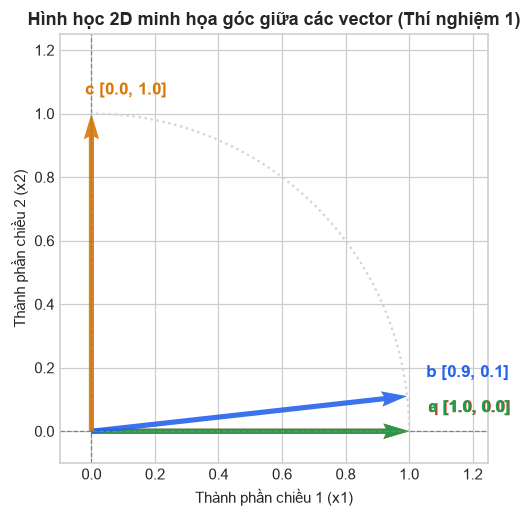

In [3]:
# Trực quan hóa hình học 2D các vector q, a, b, c trên mặt phẳng (x1, x2)
fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)

theta = np.linspace(0, np.pi / 2, 100)
ax.plot(np.cos(theta), np.sin(theta), color='lightgray', linestyle=':', label='Đường tròn đơn vị')

colors = {'q': '#DC2626', 'a': '#16A34A', 'b': '#2563EB', 'c': '#D97706'}
vec_coords = {'q': [1.0, 0.0], 'a': [1.0, 0.0], 'b': [0.9, 0.1], 'c': [0.0, 1.0]}

for label, coord in vec_coords.items():
    dx, dy = coord[0], coord[1]
    norm = np.hypot(dx, dy)
    dx_norm, dy_norm = dx / norm, dy / norm
    ax.quiver(0, 0, dx_norm, dy_norm, angles='xy', scale_units='xy', scale=1,
              color=colors[label], width=0.012, alpha=0.9)
    offset = 0.06
    ax.text(dx_norm + (offset if dx_norm > 0.5 else -0.02), dy_norm + offset,
            f'{label} {coord}', fontsize=11, fontweight='bold', color=colors[label])

ax.set_xlim(-0.1, 1.25)
ax.set_ylim(-0.1, 1.25)
ax.set_aspect('equal')
ax.set_xlabel('Thành phần chiều 1 (x1)')
ax.set_ylabel('Thành phần chiều 2 (x2)')
ax.set_title('Hình học 2D minh họa góc giữa các vector (Thí nghiệm 1)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**
1. Khi không áp dụng bộ lọc, vector $a$ cùng hướng với $q$ (khoảng cách cosine 0.0000) xếp hạng 1, tiếp theo là vector $b$ (khoảng cách 0.0062) và vector $c$ (vuông góc, khoảng cách 1.0000) xếp hạng 3.
2. Khi áp dụng bộ lọc `topic = 'Y'`, Chroma tiến hành lọc siêu dữ liệu trước (pre-filtering), loại bỏ toàn bộ các tài liệu thuộc topic X. Do đó, vector $c$ trở thành kết quả duy nhất ở hạng 1.
3. Khoảng cách cosine do Chroma trả về trùng khớp với kết quả tính toán đại số tuyến tính của NumPy. Phép lọc siêu dữ liệu làm thay đổi tập tài liệu hợp lệ được xem xét, không làm thay đổi định nghĩa khoảng cách.

## 2. Trích Xuất Vector Embedding và Lưu Trữ Corpus Tiếng Việt
*Liên hệ Slide 5–6, 8–9 và 17*

Khảo sát kho học liệu gồm 114 đoạn văn bản CNTT tiếng Việt được lập chỉ mục trong Chroma (collection `seminar_corpus_e5`) bằng mô hình nhúng đa ngôn ngữ `intfloat/multilingual-e5-small`.

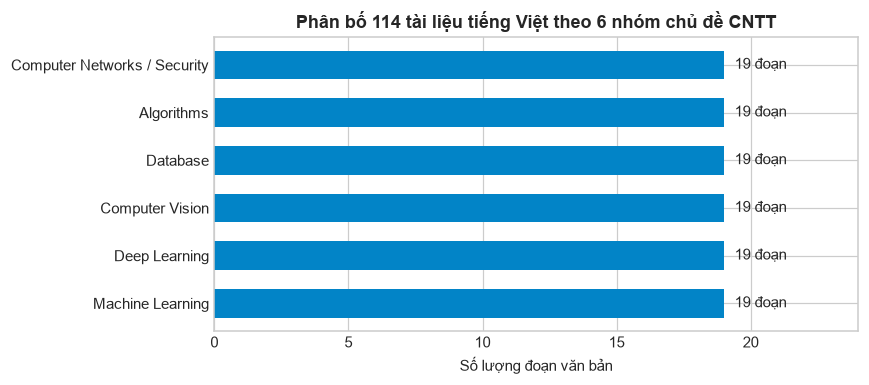

,Chủ đề CNTT,Số đoạn văn (Passages)
0,Machine Learning,19
1,Deep Learning,19
2,Computer Vision,19
3,Database,19
4,Algorithms,19
5,Computer Networks / Security,19


In [4]:
# Đọc corpus và thống kê phân bố theo chủ đề
docs = []
with open(PROJECT_ROOT / 'data/corpus/documents.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            docs.append(json.loads(line))

df_corpus = pd.DataFrame(docs)
topic_counts = df_corpus['topic'].value_counts().reset_index()
topic_counts.columns = ['Chủ đề CNTT', 'Số đoạn văn (Passages)']

# Vẽ biểu đồ phân bố chủ đề
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(topic_counts['Chủ đề CNTT'], topic_counts['Số đoạn văn (Passages)'], color='#0284C7', height=0.6)
ax.set_xlabel('Số lượng đoạn văn bản')
ax.set_title('Phân bố 114 tài liệu tiếng Việt theo 6 nhóm chủ đề CNTT', fontsize=12, fontweight='bold')
ax.set_xlim(0, 24)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.4, bar.get_y() + bar.get_height() / 2, f'{int(w)} đoạn', va='center', fontsize=10)
plt.tight_layout()
plt.show()

topic_counts

In [5]:
# Mở collection Chroma chính thức ở chế độ chỉ đọc và trích xuất một bản ghi mẫu
client = chromadb.PersistentClient(path=str(PROJECT_ROOT / 'chroma_db'))
col = client.get_collection(name='seminar_corpus_e5')
total_records = col.count()

# Lấy tài liệu mẫu db_003 (Chỉ mục B-Tree)
sample_record = col.get(ids=['db_003'], include=['embeddings', 'documents', 'metadatas'])
sample_meta = sample_record['metadatas'][0]
sample_vec = np.array(sample_record['embeddings'][0])

print(f'Collection Name:     {col.name}')
print(f'Tổng số bản ghi:     {total_records} tài liệu')
print(f'Độ đo khoảng cách:   {col.metadata.get("hnsw:space", "cosine")}')
print(f'Mã tài liệu mẫu:     db_003')
print(f'Tiêu đề:             {sample_meta.get("title")}')
print(f'Chủ đề:              {sample_meta.get("topic")}')
print(f'Số chiều vector:     {len(sample_vec)} chiều (Dimensions)')
print(f'Chuẩn L2 vector:     {np.linalg.norm(sample_vec):.6f} (Độ dài vector đơn vị)')
print(f'Mẫu 6 giá trị đầu:   {np.round(sample_vec[:6], 4)}')
print(f'Đoạn văn bản trích:  "{sample_record["documents"][0][:130]}..."')

Collection Name:     seminar_corpus_e5
Tổng số bản ghi:     114 tài liệu
Độ đo khoảng cách:   cosine
Mã tài liệu mẫu:     db_003
Tiêu đề:             Chỉ mục B-Tree và B+Tree trong Cơ sở Dữ liệu
Chủ đề:              Database
Số chiều vector:     384 chiều (Dimensions)
Chuẩn L2 vector:     1.000000 (Độ dài vector đơn vị)
Mẫu 6 giá trị đầu:   [ 0.0748 -0.0712 -0.0439 -0.0386  0.0982 -0.065 ]
Đoạn văn bản trích:  "Chỉ mục B-Tree (và biến thể B+Tree phổ biến) là cấu trúc cây tìm kiếm tự cân bằng nhiều nhánh được thiết kế tối ưu cho các thiết b..."


**Nhận xét:**
1. Kho tài liệu 114 đoạn được phân bố cân bằng (19 đoạn mỗi chủ đề) trên 6 lĩnh vực CNTT quan trọng.
2. Mô hình `multilingual-e5-small` nén thông tin ngữ nghĩa của đoạn văn bản thành một vector 384 chiều đã được chuẩn hóa L2 (độ dài vector bằng 1.0).
3. Phân định rạch ròi kiến trúc: **Mô hình E5 đảm nhiệm việc biểu diễn ngữ nghĩa dạng vector, còn Chroma đóng vai trò cơ sở dữ liệu chuyên dụng để quản lý khóa ID, lưu trữ siêu dữ liệu và tối ưu hóa việc tìm kiếm láng giềng gần nhất trên đĩa cứng.**

## 3. Đối Sánh Tìm Kiếm Ngữ Nghĩa (Chroma) và Tìm Kiếm Từ Khóa (BM25)
*Liên hệ Slide 3–4*

Thí nghiệm so sánh kết quả Top-5 giữa Chroma Semantic Search (vector dense) và BM25 (sparse lexical) trên cùng 114 tài liệu với 3 câu hỏi thuộc tập phát triển (Dev split):
- `q_001`: Tìm vật thể và vị trí trong ảnh (diễn đạt tự nhiên, paraphrase)
- `q_005`: Ngăn chặn mã độc nhập vào ô tìm kiếm phá CSDL (thuật ngữ an ninh ứng dụng)
- `q_019`: Sự khác biệt giữa điều chuẩn L1 Lasso và điều chuẩn L2 Ridge (đối chiếu khái niệm kỹ thuật)

In [6]:
# Nạp module truy xuất Chroma và BM25 từ thư mục mã nguồn dự án
from src.chroma_search import ChromaRetriever
from src.bm25_search import BM25Retriever

# Khởi tạo trước mô hình và index trong khối tĩnh để không in log tiến trình
with suppress_initialization_noise():
    chroma_retriever = ChromaRetriever(db_path=str(PROJECT_ROOT / 'chroma_db'))
    bm25_retriever = BM25Retriever(data_path=str(PROJECT_ROOT / 'data/corpus/documents.jsonl'))
    chroma_retriever.search('warmup', top_k=1)
    bm25_retriever.search('warmup', top_k=1)

# Đọc 3 truy vấn dev trực tiếp từ data/eval/queries.jsonl
dev_target_ids = ['q_001', 'q_005', 'q_019']
dev_queries_dict = {}
with open(PROJECT_ROOT / 'data/eval/queries.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            q = json.loads(line)
            if q['query_id'] in dev_target_ids:
                dev_queries_dict[q['query_id']] = q['query']

dev_queries = [(qid, dev_queries_dict[qid]) for qid in dev_target_ids if qid in dev_queries_dict]

# Chạy truy vấn và hiển thị bảng đối chiếu Top-5 cho từng câu hỏi
for qid, qtext in dev_queries:
    c_top5 = chroma_retriever.search(qtext, top_k=5)
    b_top5 = bm25_retriever.search(qtext, top_k=5)
    
    rows = []
    for rank in range(1, 6):
        c_item = c_top5[rank - 1]
        b_item = b_top5[rank - 1]
        rows.append({
            'Hạng': rank,
            'Chroma ID': c_item['id'],
            'Tiêu đề (Chroma)': c_item['title'][:32],
            'Cosine Dist': round(c_item['distance'], 4),
            'BM25 ID': b_item['id'],
            'Tiêu đề (BM25)': b_item['title'][:32],
            'BM25 Score': round(b_item['score'], 4),
        })
    
    print(f'=== TRUY VẤN {qid}: "{qtext}" ===')
    df_q = pd.DataFrame(rows)
    display(df_q)
    print()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

=== TRUY VẤN q_001: "làm thế nào để máy tính tự động tìm ra các vật thể và vị trí của chúng trong một bức ảnh?" ===


,Hạng,Chroma ID,Tiêu đề (Chroma),Cosine Dist,BM25 ID,Tiêu đề (BM25),BM25 Score
0,1,cv_009,Bài toán Phân loại Ảnh Image Cla,0.1452,cv_009,Bài toán Phân loại Ảnh Image Cla,13.1526
1,2,cv_014,Phân đoạn Cá thể Instance Segmen,0.1504,cv_003,Khái niệm Trường Thụ nhận Recept,12.0950
2,3,cv_018,Trích xuất Đặc trưng Truyền thốn,0.1614,cv_008,Vision Transformer ViT trong Thị,11.6684
3,4,cv_008,Vision Transformer ViT trong Thị,0.1663,net_017,Tấn công Từ chối Dịch vụ Phân tá,11.3555
4,5,ml_009,Máy vector hỗ trợ SVM và Kernel,0.1681,cv_004,Mạng AlexNet và Bước đột phá Học,10.7518



=== TRUY VẤN q_005: "làm sao để ngăn chặn người dùng nhập mã độc vào ô tìm kiếm nhằm phá hoại cơ sở dữ liệu web" ===


,Hạng,Chroma ID,Tiêu đề (Chroma),Cosine Dist,BM25 ID,Tiêu đề (BM25),BM25 Score
0,1,net_012,Lỗ hổng Cross-Site Scripting XSS,0.1319,net_011,Lỗ hổng SQL Injection và Phòng t,13.3263
1,2,net_011,Lỗ hổng SQL Injection và Phòng t,0.1344,net_013,Lỗ hổng Tấn công CSRF và Mã phòn,12.7854
2,3,net_017,Tấn công Từ chối Dịch vụ Phân tá,0.1452,net_012,Lỗ hổng Cross-Site Scripting XSS,11.4850
3,4,net_013,Lỗ hổng Tấn công CSRF và Mã phòn,0.1546,algo_006,Bảng Băm Hash Table và Xử lý Xun,10.5543
4,5,algo_006,Bảng Băm Hash Table và Xử lý Xun,0.1606,db_015,Cơ sở Dữ liệu Vector Vector Data,6.7904



=== TRUY VẤN q_019: "sự khác biệt giữa điều chuẩn L1 Lasso và điều chuẩn L2 Ridge" ===


,Hạng,Chroma ID,Tiêu đề (Chroma),Cosine Dist,BM25 ID,Tiêu đề (BM25),BM25 Score
0,1,ml_005,Điều chuẩn L2 Ridge và Suy giảm,0.1310,dl_008,Kỹ thuật Chuẩn hóa Batch Normali,14.3032
1,2,ml_004,Điều chuẩn L1 Lasso và Chọn lọc,0.1326,ml_005,Điều chuẩn L2 Ridge và Suy giảm,13.7851
2,3,db_017,Các Độ đo Khoảng cách Vector Cos,0.1658,ml_004,Điều chuẩn L1 Lasso và Chọn lọc,13.0586
3,4,dl_009,Kỹ thuật Chuẩn hóa Layer Normali,0.1716,cv_004,Mạng AlexNet và Bước đột phá Học,11.4004
4,5,db_001,Mô hình Cơ sở Dữ liệu Quan hệ RD,0.1719,ml_015,Hiện tượng Quá khớp và các Biện,10.7109


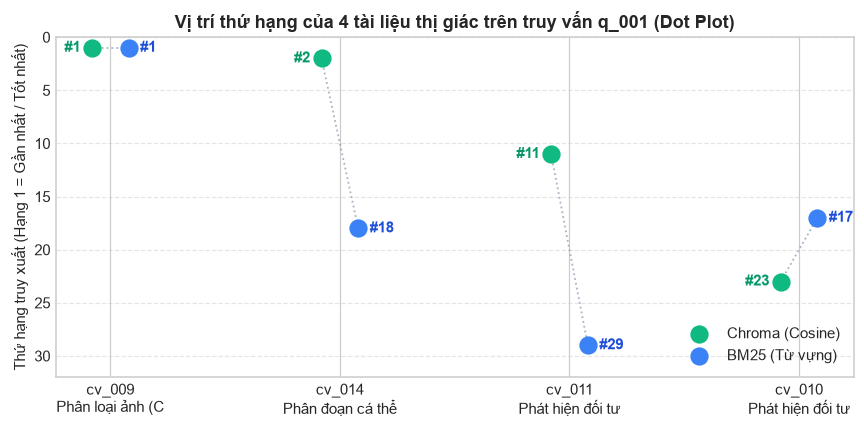

,Mã tài liệu,Nội dung chính,Thứ hạng Chroma,Thứ hạng BM25
0,cv_009,Phân loại ảnh (Classification),1,1
1,cv_014,Phân đoạn cá thể (Mask R-CNN),2,18
2,cv_011,Phát hiện đối tượng (YOLO),11,29
3,cv_010,Phát hiện đối tượng (Faster R-CNN),23,17


In [7]:
# Phân tích trường hợp truy vấn q_001: Khảo sát thứ tự của 4 tài liệu thị giác liên quan
# cv_009: Image Classification | cv_010: Faster R-CNN | cv_011: YOLO | cv_014: Mask R-CNN
q_001_text = dev_queries[0][1]
c_all = chroma_retriever.search(q_001_text, top_k=114)
b_all = bm25_retriever.search(q_001_text, top_k=114)

target_ids = {
    'cv_009': 'Phân loại ảnh (Classification)',
    'cv_014': 'Phân đoạn cá thể (Mask R-CNN)',
    'cv_011': 'Phát hiện đối tượng (YOLO)',
    'cv_010': 'Phát hiện đối tượng (Faster R-CNN)',
}

c_ranks = {r['id']: r['rank'] for r in c_all}
b_ranks = {r['id']: r['rank'] for r in b_all}

df_targets = pd.DataFrame([
    {
        'Mã tài liệu': did,
        'Nội dung chính': desc,
        'Thứ hạng Chroma': c_ranks.get(did, '>114'),
        'Thứ hạng BM25': b_ranks.get(did, '>114'),
    }
    for did, desc in target_ids.items()
])

# Trực quan hóa thứ hạng bằng Dot Plot (trục Y đảo ngược: Hạng 1 ở đỉnh cao nhất)
fig, ax = plt.subplots(figsize=(8, 4.0))
x = np.arange(len(target_ids))
chroma_vals = [c_ranks[did] for did in target_ids]
bm25_vals = [b_ranks[did] for did in target_ids]

ax.grid(True, linestyle='--', alpha=0.5, axis='y')
ax.scatter(x - 0.08, chroma_vals, color='#10B981', s=120, zorder=4, label='Chroma (Cosine)')
ax.scatter(x + 0.08, bm25_vals, color='#3B82F6', s=120, zorder=4, label='BM25 (Từ vựng)')

for i in range(len(target_ids)):
    ax.plot([x[i] - 0.08, x[i] + 0.08], [chroma_vals[i], bm25_vals[i]], color='#94A3B8', linestyle=':', linewidth=1.2, alpha=0.8)
    c_y = chroma_vals[i]
    b_y = bm25_vals[i]
    ax.text(x[i] - 0.13, c_y, f'#{c_y}', ha='right', va='center', fontsize=10, fontweight='bold', color='#059669')
    ax.text(x[i] + 0.13, b_y, f'#{b_y}', ha='left', va='center', fontsize=10, fontweight='bold', color='#1D4ED8')

ax.set_ylabel('Thứ hạng truy xuất (Hạng 1 = Gần nhất / Tốt nhất)')
ax.set_title('Vị trí thứ hạng của 4 tài liệu thị giác trên truy vấn q_001 (Dot Plot)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([f'{did}\n{desc[:16]}' for did, desc in target_ids.items()], fontsize=9.5)
ax.set_ylim(32, 0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

df_targets

**Nhận xét:**
1. Trên $q_{001}$, cả hai phương pháp đều xếp `cv_009` (Phân loại ảnh) ở vị trí số 1. Giả thuyết giải thích dựa trên đặc trưng văn bản là đoạn `cv_009` chứa tần suất cao các từ vựng chung với câu hỏi như 'bức ảnh' và 'máy tính'. Tài liệu `cv_014` (Phân đoạn cá thể) được Chroma xếp ở hạng 2 (khoảng cách 0.1504 rất sát 0.1452) do văn bản có chứa các cụm từ mô tả vị trí đối tượng.
2. Trên $q_{005}$, BM25 xếp tài liệu SQL Injection (`net_011`) ở hạng 1 nhờ trùng khớp trực tiếp cụm từ 'cơ sở dữ liệu'. Chroma đưa nhóm tài liệu an ninh web (XSS, SQLi, DDoS, CSRF) vào toàn bộ Top-4.
3. Trên $q_{019}$, Chroma xếp hai tài liệu đối chiếu L2 Ridge (`ml_005`) và L1 Lasso (`ml_004`) ở Top-1 và Top-2, trong khi BM25 bị ảnh hưởng bởi tần suất từ 'chuẩn hóa' nên xếp tài liệu Batch Normalization ở hạng 1.
4. Ba truy vấn dev cho thấy sự khác biệt về mặt thứ hạng giữa cơ chế nhúng ngữ nghĩa dày đặc và đối sánh từ khóa thưa thớt. Tuy nhiên, kết quả này chỉ là các quan sát thực nghiệm trên ba câu hỏi cụ thể, chưa cấu thành bằng chứng để khái quát rằng một phương pháp là vượt trội tổng thể.

## 4. Đối Chiếu Chỉ Mục HNSW của Chroma với Tìm Kiếm Chính Xác (Exact Search)
*Liên hệ Slide 11–13 và Slide 19*

**Câu hỏi khoa học:** Trên cùng một không gian vector, chỉ mục đồ thị HNSW của Chroma có tìm lại đúng Top-5 láng giềng gần nhất so với phép tính khoảng cách cosine vét cạn (exhaustive exact search) trên toàn bộ kho tài liệu hay không?

Chỉ số đánh giá độ tái hồi láng giềng gần đúng:
$$\text{ANN Recall@5} = \frac{|\text{Top-5}_{\text{Chroma HNSW}} \cap \text{Top-5}_{\text{Exact Cosine}}|}{5}$$

In [8]:
# Lấy toàn bộ vector đã lưu trong Chroma collection seminar_corpus_e5
stored_data = col.get(include=['embeddings', 'documents', 'metadatas'])
corpus_ids = stored_data['ids']
corpus_embeddings = np.array(stored_data['embeddings'], dtype=np.float32)
print(f'Đã trích xuất ma trận embedding từ Chroma: {corpus_embeddings.shape}')

# Đối chiếu kết quả trên 3 dev queries
from sentence_transformers import SentenceTransformer
with suppress_initialization_noise():
    model = SentenceTransformer('intfloat/multilingual-e5-small', device='cpu')

ann_comparison_rows = []
recall_scores = []

for qid, qtext in dev_queries:
    # Chroma HNSW search trên index đĩa
    c_top5 = chroma_retriever.search(qtext, top_k=5)
    chroma_top5_ids = [item['id'] for item in c_top5]
    
    # Exact Cosine search tính trực tiếp trong RAM bằng NumPy
    q_vec = model.encode(f'query: {qtext.strip()}', normalize_embeddings=True, show_progress_bar=False)
    exact_distances = 1.0 - np.dot(corpus_embeddings, q_vec)
    exact_top5_indices = np.argsort(exact_distances)[:5]
    exact_top5_ids = [corpus_ids[idx] for idx in exact_top5_indices]
    
    overlap = set(chroma_top5_ids) & set(exact_top5_ids)
    recall_5 = len(overlap) / 5.0
    recall_scores.append(recall_5)
    
    ann_comparison_rows.append({
        'Mã Query': qid,
        'Chroma HNSW Top-5': ', '.join(chroma_top5_ids),
        'Exact Cosine Top-5': ', '.join(exact_top5_ids),
        'Số ID trùng khớp': f'{len(overlap)} / 5',
        'ANN Recall@5': f'{recall_5 * 100:.1f}%',
    })

df_ann = pd.DataFrame(ann_comparison_rows)
df_ann

Đã trích xuất ma trận embedding từ Chroma: (114, 384)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,Mã Query,Chroma HNSW Top-5,Exact Cosine Top-5,Số ID trùng khớp,ANN Recall@5
0,q_001,"cv_009, cv_014, cv_018, cv_008, ml_009","cv_009, cv_014, cv_018, cv_008, ml_009",5 / 5,100.0%
1,q_005,"net_012, net_011, net_017, net_013, algo_006","net_012, net_011, net_017, net_013, algo_006",5 / 5,100.0%
2,q_019,"ml_005, ml_004, db_017, dl_009, db_001","ml_005, ml_004, db_017, dl_009, db_001",5 / 5,100.0%


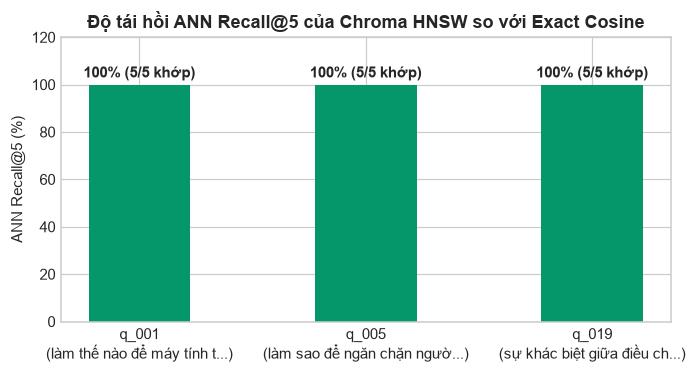

In [9]:
# Trực quan hóa tỷ lệ ANN Recall@5 trên 3 câu hỏi kiểm tra
fig, ax = plt.subplots(figsize=(6.5, 3.5))
q_labels = [f'{qid}\n({qtext[:25]}...)' for qid, qtext in dev_queries]
bars = ax.bar(q_labels, [r * 100 for r in recall_scores], color='#059669', width=0.45)
ax.set_ylabel('ANN Recall@5 (%)')
ax.set_ylim(0, 120)
ax.set_title('Độ tái hồi ANN Recall@5 của Chroma HNSW so với Exact Cosine', fontsize=12, fontweight='bold')
for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, y + 3, f'{y:.0f}% (5/5 khớp)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:**
1. Trên đúng 3 truy vấn dev được khảo sát ($q_{001}, q_{005}, q_{019}$), Top-5 của Chroma HNSW trùng khớp với phương pháp tính cosine chính xác vét cạn (ANN Recall@5 = 1.0).
2. Kết quả đo lường này cho thấy trên quy mô 114 tài liệu với các truy vấn thử nghiệm cụ thể này, thuật toán HNSW của Chroma tìm lại đúng các láng giềng gần nhất của không gian vector. Thứ hạng của `cv_009` trên $q_{001}$ phản ánh vị trí hình học của vector E5 chứ không phải do sai số lập chỉ mục.
3. Cần nhấn mạnh rằng kết quả này được ghi nhận cục bộ trên 3 truy vấn thử nghiệm với quy mô 114 tài liệu, không phải là sự chứng minh hay bảo đảm phổ quát rằng HNSW luôn đạt Recall = 100% trên mọi truy vấn hoặc trên dữ liệu lớn.

## 5. Quy Trình Đánh Giá Chất Lượng Truy Xuất và Cổng Kiểm Duyệt Nhãn
*Liên hệ Slide 19–20*

Thí nghiệm minh chứng quy trình đánh giá chuẩn khoa học: xây dựng candidate pool, định nghĩa các độ đo IR (Hit@5, MRR@5, nDCG@5) và thiết lập cơ chế kiểm soát nhãn đã xác thực (Verified-Label Gate) nhằm đảm bảo tính trung thực trong nghiên cứu.

In [10]:
# Khảo sát tiến độ kiểm duyệt trên tập Candidate Review Pool
pool_rows = []
with open(PROJECT_ROOT / 'data/eval/review_pool.csv', 'r', encoding='utf-8-sig') as f:
    reader = csv.DictReader(f)
    pool_rows = list(reader)

total_candidates = len(pool_rows)
verified_count = sum(1 for r in pool_rows if r.get('review_status') == 'verified')
pending_count = total_candidates - verified_count

# Tính tỷ lệ phần trăm động và hiển thị
pct_verified = (100.0 * verified_count / total_candidates) if total_candidates > 0 else 0.0
pct_pending = (100.0 * pending_count / total_candidates) if total_candidates > 0 else 0.0

print(f'Tổng số cặp (query, doc) trong Review Pool: {total_candidates}')
print(f'Số dòng được đánh dấu verified:             {verified_count} ({pct_verified:.1f}%)')
print(f'Số dòng đang chờ kiểm duyệt (Pending):      {pending_count} ({pct_pending:.1f}%)')

# Hiển thị trích đoạn 5 dòng đầu tiên từ bảng kiểm duyệt
df_pool_sample = pd.DataFrame([
    {
        'Query ID': r['query_id'],
        'Câu hỏi': r['query_text'][:35] + '...',
        'Doc ID': r['doc_id'],
        'Tiêu đề tài liệu': r['doc_title'][:30],
        'Proposed Rel': r['proposed_relevance'] or '(unjudged)',
        'Verified Rel': r['verified_relevance'] or '[Trống]',
        'Trạng thái': r['review_status'],
    }
    for r in pool_rows[:5]
])
df_pool_sample

Tổng số cặp (query, doc) trong Review Pool: 105
Số dòng được đánh dấu verified:             0 (0.0%)
Số dòng đang chờ kiểm duyệt (Pending):      105 (100.0%)


,Query ID,Câu hỏi,Doc ID,Tiêu đề tài liệu,Proposed Rel,Verified Rel,Trạng thái
0,q_002,cách giải quyết khi mô hình học máy...,ml_015,Hiện tượng Quá khớp và các Biệ,2,[Trống],pending
1,q_002,cách giải quyết khi mô hình học máy...,dl_018,Học chuyển giao Transfer Learn,(unjudged),[Trống],pending
2,q_002,cách giải quyết khi mô hình học máy...,dl_019,Lượng tử hóa Mô hình Học sâu M,(unjudged),[Trống],pending
3,q_002,cách giải quyết khi mô hình học máy...,ml_014,Đánh đổi Độ chệch và Phương sa,1,[Trống],pending
4,q_002,cách giải quyết khi mô hình học máy...,ml_001,Học có giám sát và Học không g,(unjudged),[Trống],pending


In [11]:
# Kiểm tra Cổng Verified-Label Gate và Xử lý Hiển thị Kết quả Đánh giá
from src.ui_helpers import check_official_benchmark_eligibility, load_preview_artifact

is_eligible, gate_reason, official_data = check_official_benchmark_eligibility(
    review_pool_path=PROJECT_ROOT / 'data/eval/review_pool.csv',
    corpus_path=PROJECT_ROOT / 'data/corpus/documents.jsonl',
    official_json_path=PROJECT_ROOT / 'results/g3/official_metrics.json'
)

if is_eligible and official_data:
    required_metrics = ['hit@5', 'mrr@5', 'ndcg@5']
    macro = official_data.get('macro_averages', {})
    c_m = macro.get('chroma', {})
    b_m = macro.get('bm25', {})
    
    def is_valid_metric(val):
        return isinstance(val, (int, float)) and np.isfinite(val) and (0.0 <= val <= 1.0)
    
    missing_c = [m for m in required_metrics if m not in c_m or not is_valid_metric(c_m[m])]
    missing_b = [m for m in required_metrics if m not in b_m or not is_valid_metric(b_m[m])]
    
    if missing_c or missing_b:
        print('>>> LỖI DỮ LIỆU ARTIFACT CHÍNH THỨC <<<')
        print('Tệp official_metrics.json thiếu hoặc chứa điểm số không hợp lệ trong [0, 1]:')
        if missing_c:
            print(f'  - Chroma thiếu hoặc không hợp lệ: {missing_c}')
        if missing_b:
            print(f'  - BM25 thiếu hoặc không hợp lệ: {missing_b}')
        print('Hệ thống từ chối hiển thị benchmark chính thức vì dữ liệu không hoàn chỉnh.\n')
    else:
        print('>>> KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC (OFFICIAL BENCHMARK) <<<')
        print('Điều kiện: 100% nhãn ứng viên trong review pool đã được xác thực.\n')
        df_macro = pd.DataFrame([
            {'Chỉ số (Metric)': 'Hit@5', 'Chroma (E5)': c_m['hit@5'], 'BM25 (PyVi)': b_m['hit@5'], 'Chênh lệch': round(c_m['hit@5'] - b_m['hit@5'], 4)},
            {'Chỉ số (Metric)': 'MRR@5', 'Chroma (E5)': c_m['mrr@5'], 'BM25 (PyVi)': b_m['mrr@5'], 'Chênh lệch': round(c_m['mrr@5'] - b_m['mrr@5'], 4)},
            {'Chỉ số (Metric)': 'nDCG@5', 'Chroma (E5)': c_m['ndcg@5'], 'BM25 (PyVi)': b_m['ndcg@5'], 'Chênh lệch': round(c_m['ndcg@5'] - b_m['ndcg@5'], 4)},
        ])
        display(df_macro)

        fig, ax = plt.subplots(figsize=(7, 3.8))
        metrics_names = ['Hit@5', 'MRR@5', 'nDCG@5']
        c_scores = [c_m['hit@5'], c_m['mrr@5'], c_m['ndcg@5']]
        b_scores = [b_m['hit@5'], b_m['mrr@5'], b_m['ndcg@5']]
        x = np.arange(len(metrics_names))
        w = 0.32
        ax.bar(x - w/2, c_scores, w, label='Chroma (E5)', color='#10B981')
        ax.bar(x + w/2, b_scores, w, label='BM25 (PyVi)', color='#3B82F6')
        ax.set_ylabel('Điểm số [0..1]')
        ax.set_ylim(0.0, 1.15)
        ax.set_xticks(x)
        ax.set_xticklabels(metrics_names, fontweight='bold')
        ax.set_title('So sánh các chỉ số truy xuất chính thức (n = 11 câu hỏi answerable)', fontsize=11, fontweight='bold')
        ax.legend()
        plt.tight_layout()
        plt.show()
else:
    print('>>> TRẠNG THÁI CỔNG KIỂM DUYỆT (VERIFIED GATE): ĐANG KHÓA AN TOÀN <<<')
    print(f'Chi tiết: {gate_reason}')
    print('Chưa có kết quả đánh giá chính thức: tập nhãn relevance đang chờ kiểm duyệt.')
    print('Tuyệt đối không sử dụng điểm số giả định để thay thế cho benchmark khoa học.\n')

# Đọc kết quả đối soát thứ hạng Top-1 từ preview artifact trên 12 test queries
preview_data = load_preview_artifact(PROJECT_ROOT / 'results/g3/rankings_preview.json')
if preview_data and 'eval_results' in preview_data:
    preview_rows = []
    for item in preview_data['eval_results']:
        c_top1 = item['chroma_top_k'][0]['doc_id'] if item['chroma_top_k'] else 'N/A'
        b_top1 = item['bm25_top_k'][0]['doc_id'] if item['bm25_top_k'] else 'N/A'
        agree = 'Trùng khớp' if item['top1_match'] else 'Khác biệt'
        if item['is_unanswerable']:
            agree += ' (Unanswerable)'
        preview_rows.append({
            'Query ID': item['query_id'],
            'Thể loại': item['category'],
            'Chroma Top-1': c_top1,
            'BM25 Top-1': b_top1,
            'Đồng thuận Top-1': agree,
        })
    
    df_preview = pd.DataFrame(preview_rows)
    display(df_preview)
    
    agr_cnt = preview_data['agreement']['top1_agreement_count']
    total_q = preview_data['subset']['total_queries']
    print(f'Tỷ lệ đồng thuận Top-1: {agr_cnt}/{total_q} ({round(100.0 * agr_cnt / total_q, 1)}%)')

>>> TRẠNG THÁI CỔNG KIỂM DUYỆT (VERIFIED GATE): ĐANG KHÓA AN TOÀN <<<
Chi tiết: Official benchmark is pending human verification (105/105 candidate labels pending).
Chưa có kết quả đánh giá chính thức: tập nhãn relevance đang chờ kiểm duyệt.
Tuyệt đối không sử dụng điểm số giả định để thay thế cho benchmark khoa học.



,Query ID,Thể loại,Chroma Top-1,BM25 Top-1,Đồng thuận Top-1
0,q_002,semantic_paraphrase,ml_015,ml_015,Trùng khớp
1,q_003,semantic_paraphrase,algo_016,db_001,Khác biệt
2,q_006,semantic_paraphrase,dl_017,dl_015,Khác biệt
3,q_010,semantic_paraphrase,dl_016,dl_019,Khác biệt
4,q_013,direct_technical,db_002,db_002,Trùng khớp
5,q_016,direct_technical,db_016,db_016,Trùng khớp
6,q_020,ambiguous_confusable,cv_014,cv_014,Trùng khớp
7,q_021,ambiguous_confusable,net_004,net_006,Khác biệt
8,q_024,ambiguous_confusable,net_015,net_015,Trùng khớp
9,q_026,exact_match,cv_012,cv_012,Trùng khớp


Tỷ lệ đồng thuận Top-1: 7/12 (58.3%)


In [12]:
# Phân tích định tính truy vấn ngoài phạm vi (Unanswerable query q_030)
unans_item = next(item for item in preview_data['eval_results'] if item['is_unanswerable'])
print(f'Truy vấn q_030: "{unans_item["query_text"]}"')
print(f'- Chroma láng giềng gần nhất: {unans_item["chroma_top_k"][0]["doc_id"]} (Khoảng cách: {unans_item["chroma_top_k"][0]["distance"]})')
print(f'- BM25 láng giềng gần nhất:   {unans_item["bm25_top_k"][0]["doc_id"]} (Điểm BM25: {unans_item["bm25_top_k"][0]["score"]})')
print('\nNhận xét: Cả hai phương pháp đều không có cơ chế tự từ chối (abstain).')
print('Khoảng cách vector gần nhất không đồng nghĩa với câu trả lời đúng.')
print('Vì vậy câu hỏi này được phân tích độc lập và loại khỏi mẫu số tính điểm trung bình Hit/MRR/nDCG.')

Truy vấn q_030: "thuật toán đồng thuận Proof of Stake và xử lý phân nhánh blockchain Ethereum"
- Chroma láng giềng gần nhất: algo_014 (Khoảng cách: 0.1513)
- BM25 láng giềng gần nhất:   ml_001 (Điểm BM25: 9.0677)

Nhận xét: Cả hai phương pháp đều không có cơ chế tự từ chối (abstain).
Khoảng cách vector gần nhất không đồng nghĩa với câu trả lời đúng.
Vì vậy câu hỏi này được phân tích độc lập và loại khỏi mẫu số tính điểm trung bình Hit/MRR/nDCG.


**Nhận xét & Tổng kết:**
1. Quy trình đánh giá phân định rạch ròi giữa thuật toán xếp hạng và ground truth đã được con người thẩm định. Việc từ chối công bố điểm benchmark khi nhãn còn pending là nguyên tắc liêm chính khoa học bắt buộc.
2. Đánh giá dựa trên candidate pool (pooled judgments) phản ánh tính tương đối của pool ứng viên chứ chưa bao quát toàn bộ corpus. Khi người kiểm duyệt hoàn tất xác thực 105 nhãn, hệ thống sẽ tự động tính toán Hit@5, MRR@5 và nDCG@5 chính thức.